# Time Series Classification Explanations on UCR Earthquakes with TS-MULE

This notebook demonstrates how to use `tsmule` to explain a black-box time series classifier on the **Earthquakes** dataset (univariate seismic readings, 512 time steps per sample) across **all 7 TS-MULE segmentation strategies**, visualize the resulting attributions side by side, and evaluate faithfulness using `PerturbationAnalysis`.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.metrics import accuracy_score, brier_score_loss, roc_auc_score

if os.path.exists('earthquakes_classification.py') and os.path.abspath('../..') not in sys.path:
    sys.path.insert(0, os.path.abspath('../..'))

from examples.earthquakes.earthquakes_classification import (
    EARTHQUAKES_METHODS,
    build_segmenter,
    load_earthquakes,
    plot_methods_relevance,
    plot_perturbation_comparison,
    train_earthquakes_classifier,
)
from tsmule.xai.evaluation import PerturbationAnalysis
from tsmule.xai.lime import LimeTS

## 1. Load Earthquakes and Train a Classifier

In [2]:
X_train, y_train, X_test, y_test = load_earthquakes()
print(f'Train: {X_train.shape}, Test: {X_test.shape}')

model = train_earthquakes_classifier(X_train, y_train, seed=42)
probs_test = model.predict_proba(X_test)[:, 1]
print(
    f'Test Accuracy: {accuracy_score(y_test, model.predict(X_test)):.4f} | '
    f'ROC-AUC: {roc_auc_score(y_test, probs_test):.4f} | '
    f'Brier: {brier_score_loss(y_test, probs_test):.4f}'
)

Train: (322, 512), Test: (139, 512)


Test Accuracy: 0.7482 | ROC-AUC: 0.7190 | Brier: 0.1717


## 2. Explain a Positive Earthquake Instance Across All 7 TS-MULE Methods

Using `partitions=50` and `win_length=10` across all 7 segmentation strategies on a positive test sample (`y == 1`).

uniform           | segments=52 | R2=0.675


exponential       | segments= 7 | R2=0.759


slopes-sorted     | segments=51 | R2=0.764
slopes-not-sorted | segments=51 | R2=0.561


bins-min          | segments=17 | R2=0.888
bins-max          | segments=34 | R2=0.791


/home/wiss/schlegel/miniconda/lib/python3.13/site-packages/pyts/preprocessing/discretizer.py:168: UserWarning: Some quantiles are equal. The number of bins will be smaller for sample [0]. Consider decreasing the number of bins or removing these samples.
  warn("Some quantiles are equal. The number of bins will "


/home/wiss/schlegel/miniconda/lib/python3.13/site-packages/pyts/preprocessing/discretizer.py:168: UserWarning: Some quantiles are equal. The number of bins will be smaller for sample [0]. Consider decreasing the number of bins or removing these samples.
  warn("Some quantiles are equal. The number of bins will "


sax               | segments=155 | R2=0.264


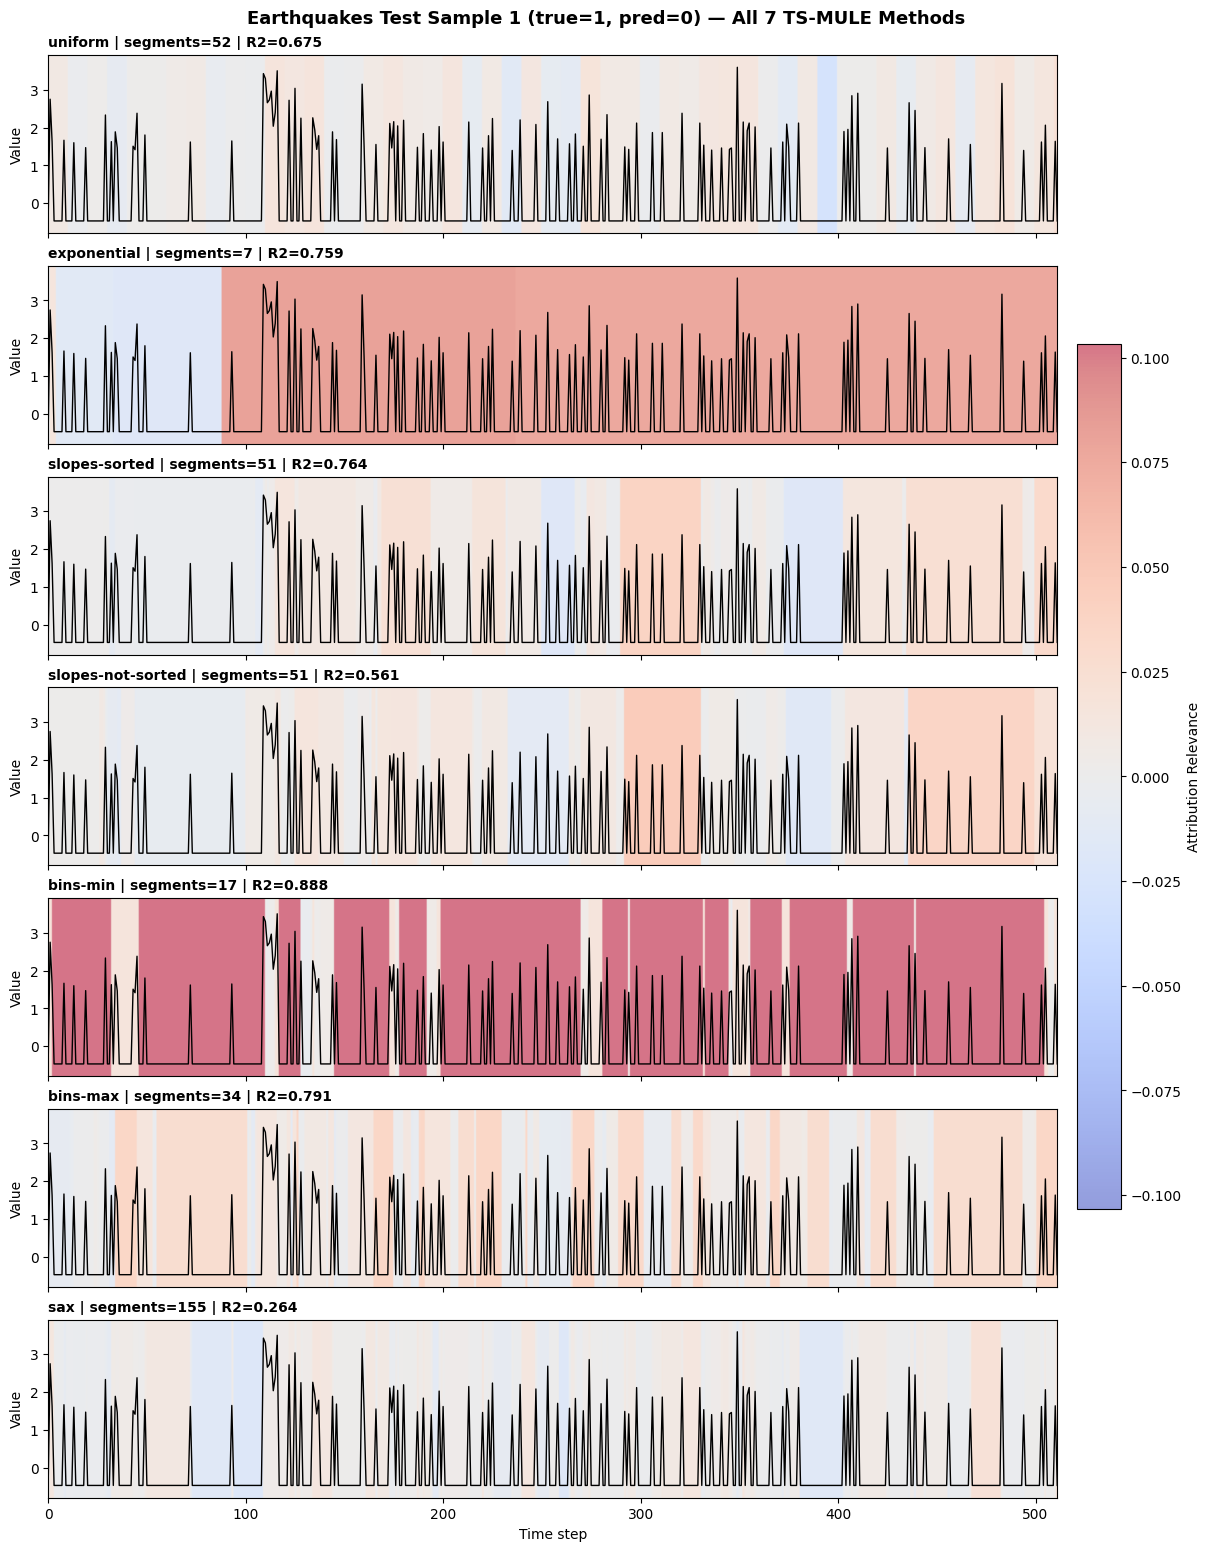

In [3]:
pos_idx = int(np.where(y_test == 1)[0][0])
sample = X_test[pos_idx]
sample_relevances = {}
sample_r2 = {}
sample_seg_counts = {}
explained_class = None

for method in EARTHQUAKES_METHODS:
    segmenter, seg_method = build_segmenter(method, partitions=50, win_length=10)
    seg_mask = (
        segmenter.segment(sample)
        if seg_method is None
        else segmenter.segment(sample, segmentation_method=seg_method)
    )
    sample_seg_counts[method] = int(len(np.unique(seg_mask)))

    explainer = LimeTS(
        kernel=Ridge(alpha=1.0),
        segmenter=segmenter,
        replace_method='zeros',
        n_samples=200,
        random_state=42,
    )
    rel = explainer.explain(
        sample,
        model.predict_proba,
        segmentation_method=seg_method,
        batch_predict=True,
    )
    explained_class = explainer.target_class
    sample_relevances[method] = rel
    sample_r2[method] = explainer.score
    print(f'{method:17s} | segments={sample_seg_counts[method]:2d} | R2={explainer.score:.3f}')

fig = plot_methods_relevance(
    sample,
    sample_relevances,
    r2_by_method=sample_r2,
    seg_counts=sample_seg_counts,
    title=f'Earthquakes Test Sample {pos_idx} (true={y_test[pos_idx]}, pred={explained_class}) — All 7 TS-MULE Methods',
)
plt.show()

## 3. Evaluate All 7 Methods with `PerturbationAnalysis`

uniform           | R2=0.699 | auc(o/r/p)=0.640/0.628/0.659 (valid=False, score=1.67) | brier(o/r/p)=0.205/0.202/0.200 (valid=False, score=1.50)


exponential       | R2=0.799 | auc(o/r/p)=0.640/0.640/0.640 (valid=True, score=nan) | brier(o/r/p)=0.205/0.205/0.205 (valid=True, score=nan)


slopes-sorted     | R2=0.740 | auc(o/r/p)=0.640/0.662/0.669 (valid=False, score=1.32) | brier(o/r/p)=0.205/0.198/0.196 (valid=False, score=1.36)


slopes-not-sorted | R2=0.728 | auc(o/r/p)=0.640/0.661/0.580 (valid=False, score=2.73) | brier(o/r/p)=0.205/0.199/0.205 (valid=False, score=0.05)


bins-min          | R2=0.918 | auc(o/r/p)=0.640/0.631/0.624 (valid=True, score=1.77) | brier(o/r/p)=0.205/0.206/0.208 (valid=True, score=4.82)


bins-max          | R2=0.781 | auc(o/r/p)=0.640/0.680/0.608 (valid=False, score=0.79) | brier(o/r/p)=0.205/0.199/0.204 (valid=False, score=0.12)


... (46 outputs left out)

/home/wiss/schlegel/miniconda/lib/python3.13/site-packages/pyts/preprocessing/discretizer.py:168: UserWarning: Some quantiles are equal. The number of bins will be smaller for sample [0]. Consider decreasing the number of bins or removing these samples.
  warn("Some quantiles are equal. The number of bins will "


/home/wiss/schlegel/miniconda/lib/python3.13/site-packages/pyts/preprocessing/discretizer.py:168: UserWarning: Some quantiles are equal. The number of bins will be smaller for sample [0]. Consider decreasing the number of bins or removing these samples.
  warn("Some quantiles are equal. The number of bins will "


/home/wiss/schlegel/miniconda/lib/python3.13/site-packages/pyts/preprocessing/discretizer.py:168: UserWarning: Some quantiles are equal. The number of bins will be smaller for sample [0]. Consider decreasing the number of bins or removing these samples.
  warn("Some quantiles are equal. The number of bins will "


sax               | R2=0.239 | auc(o/r/p)=0.640/0.638/0.640 (valid=False, score=0.00) | brier(o/r/p)=0.205/0.200/0.201 (valid=False, score=0.74)


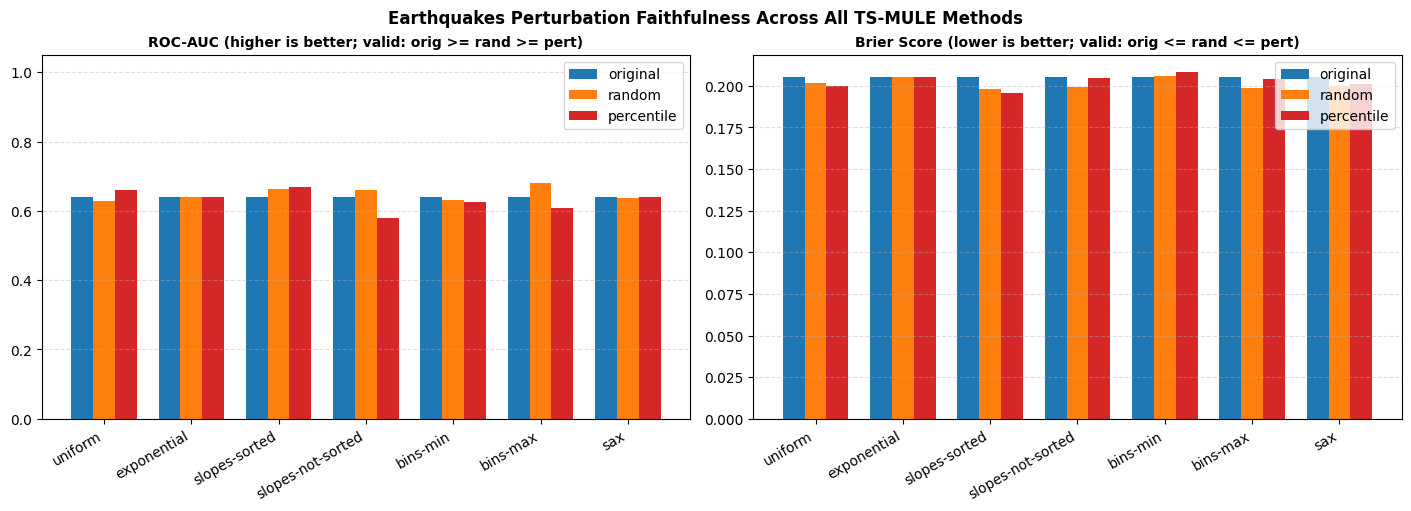

In [4]:
rng = np.random.default_rng(42)
eval_idx = rng.permutation(len(X_test))[:60]
X_sub = X_test[eval_idx]
y_sub = y_test[eval_idx]
eval_results = {}

for method in EARTHQUAKES_METHODS:
    segmenter, seg_method = build_segmenter(method, partitions=50, win_length=10)
    explainer = LimeTS(
        kernel=Ridge(alpha=1.0),
        segmenter=segmenter,
        replace_method='zeros',
        n_samples=200,
        random_state=42,
    )
    relevances = []
    r2_scores = []
    for x in X_sub:
        relevances.append(
            explainer.explain(
                x,
                model.predict_proba,
                segmentation_method=seg_method,
                batch_predict=True,
            )
        )
        r2_scores.append(explainer.score)
    relevances = np.asarray(relevances)

    pa_auc = PerturbationAnalysis()
    auc_ins = pa_auc.analysis_relevance(
        X_sub,
        y_sub,
        relevances,
        predict_fn=lambda batch: model.predict_proba(batch)[:, 1],
        eval_fn=roc_auc_score,
        replace_method='zeros',
        percentile=80,
        use_abs=True,
        random_state=42,
    )

    pa_brier = PerturbationAnalysis()
    brier_ins = pa_brier.analysis_relevance(
        X_sub,
        y_sub,
        relevances,
        predict_fn=lambda batch: model.predict_proba(batch)[:, 1],
        eval_fn=brier_score_loss,
        replace_method='zeros',
        percentile=80,
        use_abs=True,
        random_state=42,
    )

    eval_results[method] = {
        'mean_r2': float(np.mean(r2_scores)),
        'auc': auc_ins,
        'auc_valid': pa_auc.is_valid(higher_is_better=True),
        'auc_score': pa_auc.perturbation_score(),
        'brier': brier_ins,
        'brier_valid': pa_brier.is_valid(higher_is_better=False),
        'brier_score': pa_brier.perturbation_score(),
    }
    print(
        f"{method:17s} | R2={eval_results[method]['mean_r2']:.3f} | "
        f"auc(o/r/p)={auc_ins['original']:.3f}/{auc_ins['random']:.3f}/{auc_ins['percentile']:.3f} "
        f"(valid={eval_results[method]['auc_valid']}, score={eval_results[method]['auc_score']:.2f}) | "
        f"brier(o/r/p)={brier_ins['original']:.3f}/{brier_ins['random']:.3f}/{brier_ins['percentile']:.3f} "
        f"(valid={eval_results[method]['brier_valid']}, score={eval_results[method]['brier_score']:.2f})"
    )

fig_eval = plot_perturbation_comparison(eval_results)
plt.show()